# Finite differences for the Poisson equation

We solve


$$
-u''(x)=f(x), \qquad 0<x<1,
$$


with Dirichlet boundary conditions


$$
u(0)=1, \qquad u(1)=2.
$$


We will compare:
1. a smooth source;
2. a discontinuous source.

Both examples have known exact solutions. This lets us measure the
numerical error rather than judge accuracy only by looking at a plot.

### Learning goals

- Build and solve a finite-difference system.
- Include nonzero boundary values correctly.
- Measure the error as the grid is refined.
- See why second-order convergence needs smoothness assumptions.

In [1]:
# If necessary, uncomment and run this line:
# %pip install numpy scipy matplotlib

import numpy as np
import matplotlib.pyplot as plt

from scipy.sparse import diags
from scipy.sparse.linalg import spsolve

## 1. The finite-difference method

Divide the interval into $M$ equal subintervals:


$$
h=\frac{1}{M}, \qquad x_i=ih,\qquad i=0,\ldots,M.
$$


There are $M-1$ unknown interior values. We approximate


$$
-u''(x_i)
\approx
\frac{-U_{i-1}+2U_i-U_{i+1}}{h^2}.
$$


Therefore, the interior unknowns satisfy


$$
\frac{1}{h^2}
\begin{pmatrix}
2 & -1 & & \\
-1 & 2 & \ddots & \\
& \ddots & \ddots & -1\\
& & -1 & 2
\end{pmatrix}
\begin{pmatrix}
U_1\\ U_2\\ \vdots\\ U_{M-1}
\end{pmatrix}
=
\begin{pmatrix}
f(x_1)\\ f(x_2)\\ \vdots\\ f(x_{M-1})
\end{pmatrix}
+
\frac{1}{h^2}
\begin{pmatrix}
u(0)\\ 0\\ \vdots\\ u(1)
\end{pmatrix}.
$$


Known boundary values are moved to the right-hand side with a **positive**
sign.

The matrix is symmetric and tridiagonal. Julia can store and solve it
efficiently without creating a full matrix.

In [2]:
def solve_poisson(f, M, g_left=1.0, g_right=2.0):
    """
    Solve -u'' = f on (0, 1), with prescribed endpoint values.

    Parameters
    ----------
    f : callable
        Source function, accepting a NumPy array.
    M : int
        Number of subintervals; use M >= 3.
    g_left, g_right : float
        Boundary values at x=0 and x=1.

    Returns
    -------
    x : array
        All grid points, including the endpoints.
    U : array
        Numerical solution, including the boundary values.
    """
    if M < 3:
        raise ValueError("Use at least 3 subintervals.")

    h = 1.0 / M
    x = np.linspace(0.0, 1.0, M + 1)
    n = M - 1  # Number of interior unknowns

    # Matrix approximating -u''
    main_diagonal = 2.0 * np.ones(n)
    off_diagonal = -np.ones(n - 1)

    A = diags(
        [off_diagonal, main_diagonal, off_diagonal],
        offsets=[-1, 0, 1],
        format="csc",
    ) / h**2

    # Source sampled at the interior grid points
    b = np.array(f(x[1:-1]), dtype=float, copy=True)

    # Add the known boundary contributions
    b[0] += g_left / h**2
    b[-1] += g_right / h**2

    # Solve for the interior unknowns
    U = np.empty(M + 1)
    U[0] = g_left
    U[-1] = g_right
    U[1:-1] = spsolve(A, b)

    return x, U

## 2. Smooth and rough sources

### Smooth example

Choose


$$
f_{\mathrm{smooth}}(x)=\pi^2\sin(\pi x).
$$


The exact solution is


$$
u_{\mathrm{smooth}}(x)=1+x+\sin(\pi x).
$$


You can check both the differential equation and the boundary conditions
by differentiation and substitution.

### Rough example: a jump in the source

Place a jump at $a=1/3$:


$$
f_{\mathrm{rough}}(x)=
\begin{cases}
1, & x<a,\\
4, & x\ge a.
\end{cases}
$$


Using $(x-a)_+=\max(x-a,0)$, the exact solution is


$$
u_{\mathrm{rough}}(x)
=
1+x+\frac{x(1-x)}{2}
+\frac{3}{2}
\left[(1-a)^2x-(x-a)_+^2\right].
$$


This solution and its first derivative are continuous. Its second
derivative jumps at $a$. The differential equation holds on either
side of the jump, and almost everywhere on the interval.

**Why choose $a=1/3$?**

We will use $M=16,32,64,\ldots$. On these grids, the jump never lands
on a grid point or halfway between two grid points. This avoids special
alignment effects that can hide the loss of accuracy.

The source value at the jump itself does not affect the exact solution;
our chosen grids never sample that point.

In [3]:
def f_smooth(x):
    return np.pi**2 * np.sin(np.pi * x)


def u_smooth(x):
    return 1.0 + x + np.sin(np.pi * x)


a = 1.0 / 3.0


def f_rough(x):
    return np.where(x < a, 1.0, 4.0)


def u_rough(x):
    positive_part = np.maximum(x - a, 0.0)

    return (
        1.0 + x
        + 0.5 * x * (1.0 - x)
        + 1.5 * ((1.0 - a)**2 * x - positive_part**2)
    )


# Check the boundary conditions
for u_exact in (u_smooth, u_rough):
    assert np.isclose(u_exact(0.0), 1.0)
    assert np.isclose(u_exact(1.0), 2.0)


# A simple check of the solver:
# -u'' = 2 with these boundary values has a quadratic solution.
def f_quadratic(x):
    return 2.0 * np.ones_like(x)


x_test, U_test = solve_poisson(f_quadratic, M=16)
u_test = 1.0 + x_test + x_test * (1.0 - x_test)

assert np.max(np.abs(U_test - u_test)) < 1e-10

print("Boundary checks and quadratic-solution test passed.")

Boundary checks and quadratic-solution test passed.


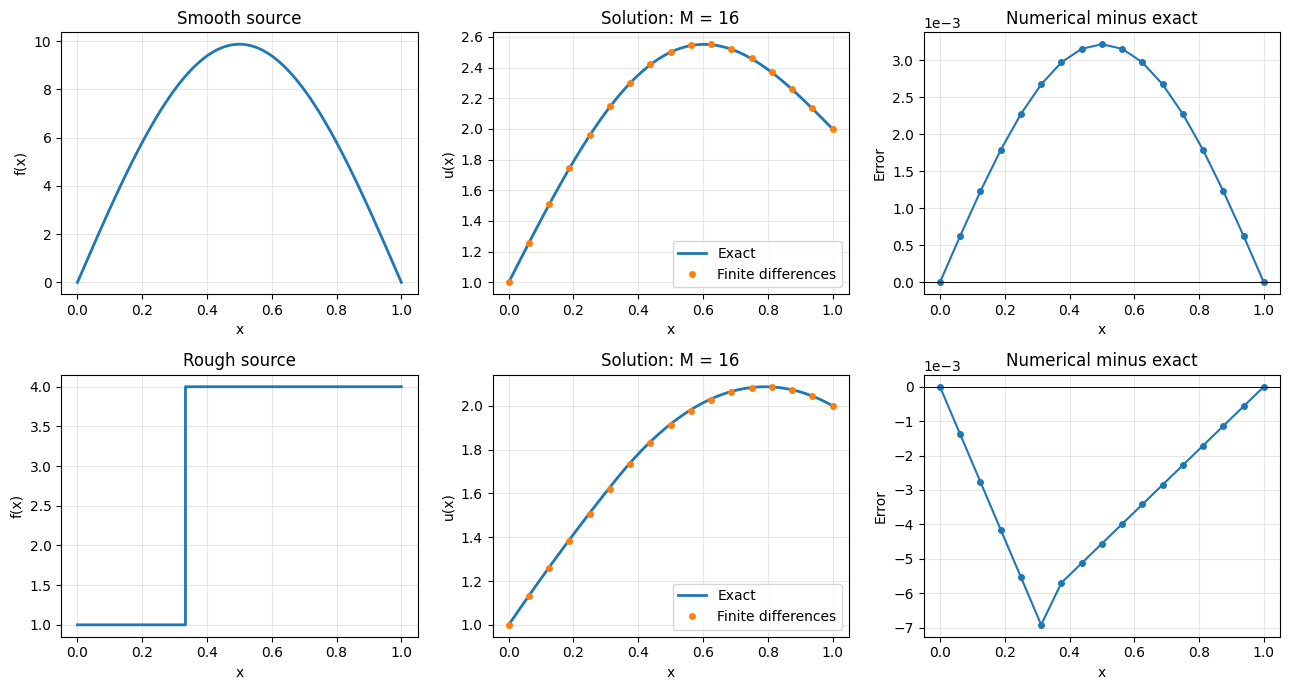

In [4]:
M = 16
x_fine = np.linspace(0.0, 1.0, 2001)

examples = [
    ("Smooth source", f_smooth, u_smooth),
    ("Rough source", f_rough, u_rough),
]

fig, axes = plt.subplots(2, 3, figsize=(13, 7))

for row, (name, f, u_exact) in enumerate(examples):
    x, U = solve_poisson(f, M)

    # Source
    ax = axes[row, 0]
    if row == 0:
        ax.plot(x_fine, f(x_fine), linewidth=2)
    else:
        ax.step(x_fine, f(x_fine), where="post", linewidth=2)

    ax.set_title(name)
    ax.set_ylabel("f(x)")

    # Exact and numerical solutions
    ax = axes[row, 1]
    ax.plot(x_fine, u_exact(x_fine), label="Exact", linewidth=2)
    ax.plot(x, U, "o", markersize=4, label="Finite differences")
    ax.set_title(f"Solution: M = {M}")
    ax.set_ylabel("u(x)")
    ax.legend()

    # Signed error
    ax = axes[row, 2]
    ax.plot(x, U - u_exact(x), "o-", markersize=4)
    ax.axhline(0.0, color="black", linewidth=0.7)
    ax.set_title("Numerical minus exact")
    ax.set_ylabel("Error")
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))

for ax in axes.flat:
    ax.set_xlabel("x")
    ax.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

## 3. How quickly does the error decrease?

A solution plot can look accurate even when the convergence rate is poor.

We measure the maximum error at the grid points:


$$
E(M)=\max_{0\le i\le M}|U_i-u(x_i)|.
$$


If the leading error behaves like


$$
E(M)\approx C h^p,
$$


then doubling $M$ halves $h$, giving


$$
\frac{E(M)}{E(2M)}\approx 2^p.
$$


Thus:

- **Second order:** halving $h$ reduces the error by approximately four.
- **First order:** halving $h$ reduces the error by approximately two.

We estimate the convergence order using


$$
p_{\mathrm{obs}}
=
\log_2\left(\frac{E(M)}{E(2M)}\right).
$$


In [5]:
def refinement_study(f, u_exact, Ms):
    """Compute maximum grid errors and observed convergence orders."""
    errors = []

    for M in Ms:
        x, U = solve_poisson(f, int(M))
        error = np.max(np.abs(U - u_exact(x)))
        errors.append(error)

    errors = np.array(errors)

    # The first grid has no previous grid for comparison.
    orders = np.full(len(Ms), np.nan)
    orders[1:] = np.log2(errors[:-1] / errors[1:])

    return errors, orders


# 16, 32, 64, ..., 1024 subintervals
Ms = 2 ** np.arange(4, 11)
hs = 1.0 / Ms

errors_smooth, orders_smooth = refinement_study(
    f_smooth, u_smooth, Ms
)

errors_rough, orders_rough = refinement_study(
    f_rough, u_rough, Ms
)


def format_order(value):
    return "   --" if np.isnan(value) else f"{value:5.2f}"


print(f"{'M':>6}  {'Smooth error':>14}  {'Order':>6}"
      f"  {'Rough error':>14}  {'Order':>6}")
print("-" * 62)

for k, M in enumerate(Ms):
    print(
        f"{M:6d}  "
        f"{errors_smooth[k]:14.5e}  "
        f"{format_order(orders_smooth[k]):>6}  "
        f"{errors_rough[k]:14.5e}  "
        f"{format_order(orders_rough[k]):>6}"
    )

     M    Smooth error   Order     Rough error   Order
--------------------------------------------------------------
    16     3.21896e-03      --     6.91732e-03      --
    32     8.03578e-04    2.00     3.63159e-03    0.93
    64     2.00822e-04    2.00     1.73569e-03    1.07
   128     5.02009e-05    2.00     8.78175e-04    0.98
   256     1.25499e-05    2.00     4.34021e-04    1.02
   512     3.13747e-06    2.00     2.17649e-04    1.00
  1024     7.84365e-07    2.00     1.08507e-04    1.00


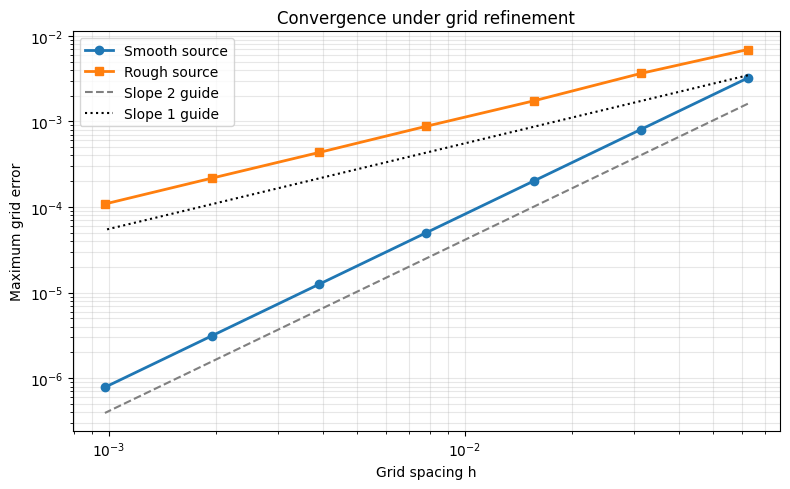

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.loglog(
    hs, errors_smooth, "o-",
    linewidth=2, label="Smooth source"
)

ax.loglog(
    hs, errors_rough, "s-",
    linewidth=2, label="Rough source"
)

# Reference lines: their vertical positions are arbitrary.
# The slopes illustrate first- and second-order convergence.
guide_second_order = 0.5 * errors_smooth[0] * (hs / hs[0])**2
guide_first_order = 0.5 * errors_rough[0] * (hs / hs[0])

ax.loglog(
    hs, guide_second_order, "--",
    color="gray", label="Slope 2 guide"
)

ax.loglog(
    hs, guide_first_order, ":",
    color="black", label="Slope 1 guide"
)

ax.set_xlabel("Grid spacing h")
ax.set_ylabel("Maximum grid error")
ax.set_title("Convergence under grid refinement")
ax.grid(True, which="both", alpha=0.3)
ax.legend()

fig.tight_layout()
plt.show()

## 4. What should we observe?

For the smooth example, the observed order should approach **two**.

For the rough example, it should approach **one**, with some variation
between refinements because the jump changes its relative position
within a grid interval.

Both methods converge, but at different rates.

### Why does the usual second-order argument fail?

For a sufficiently smooth solution, Taylor expansion gives a bound


$$
\left|
\frac{-u(x-h)+2u(x)-u(x+h)}{h^2}+u''(x)
\right|
\le
\frac{h^2}{12}\max |u^{(4)}|.
$$


Together with stability, this gives second-order convergence.

For the rough example, the solution has a jump in its second derivative.
The Taylor estimate is therefore not valid for stencils crossing the
jump.

Sampling this discontinuous source on the chosen grids also introduces
an error in how the source jump is represented. Its effect on the
solution is of order $h$, rather than $h^2$.

### Important qualification

A rough source does **not always** imply first-order convergence.

The result depends on:
- the type of roughness;
- its alignment with the grid;
- how the source and interface are discretized.

Special alignments or interface-aware methods can give better accuracy.
This notebook demonstrates the loss of second order for ordinary
pointwise source sampling on a particular sequence of grids.

## Questions to explore

1. Change the visualization from `M = 16` to `M = 64`.
   Why is the error plot more informative than the solution plot?

2. Differentiate the rough exact solution separately on $x<a$ and
   $x>a$. Check that $-u''$ equals the prescribed source.

3. Why does the rough solution look smooth even though its source jumps?

4. Change `a = 1.0 / 3.0` to another value and rerun the later cells.
   What changes if the jump lies exactly on a grid point?

5. Approximately how many times more intervals are needed to reduce
   the error by a factor of ten:
   - for a second-order method?
   - for a first-order method?

6. Why was the quadratic-solution test useful for checking the solver,
   but insufficient for measuring its general convergence order?

## 5. Conditioning: how sensitive is the linear system?

Our numerical solution satisfies


$$
A_h\mathbf U=\mathbf b.
$$


What happens if the right-hand side changes slightly?

For a perturbation $\delta\mathbf b$, the solution changes by


$$
A_h\,\delta\mathbf U=\delta\mathbf b.
$$


We distinguish two questions:

- **Absolute sensitivity:** how large is the solution change compared
  with the right-hand-side change?
- **Relative sensitivity:** how large are those changes compared
  with the original solution and right-hand side?

### The condition number

In the Euclidean norm, the condition number is


$$
\kappa_2(A_h)=\|A_h\|_2\|A_h^{-1}\|_2.
$$


For a symmetric positive definite matrix, this simplifies to


$$
\boxed{
\kappa_2(A_h)
=
\frac{\lambda_{\max}(A_h)}{\lambda_{\min}(A_h)}.
}
$$


The Poisson matrix is symmetric positive definite, and its condition
number grows as the mesh is refined. 

The condition number provides a worst-case bound on relative changes:


$$
\boxed{
\frac{\|\delta\mathbf U\|_2}{\|\mathbf U\|_2}
\le
\kappa_2(A_h)
\frac{\|\delta\mathbf b\|_2}{\|\mathbf b\|_2}.
}
$$


Here the matrix is unchanged, and the right-hand side is perturbed.

**Interpretation:** a large condition number allows large relative
amplification, but does not mean that every perturbation is strongly
amplified.

### Predicting the condition number without building a dense matrix

In this notebook, $M$ is the number of subintervals, so there are
$M-1$ interior unknowns and $h=1/M$.

For our matrix, the eigenvalues are


$$
\lambda_k
=
\frac{4}{h^2}
\sin^2\left(\frac{k\pi}{2M}\right),
\qquad k=1,\ldots,M-1.
$$


This is the lecture's eigenvalue formula with $N+1=M$.
[NumericsPDEs_CES_.pdf]

Thus,


$$
\lambda_{\min}
=
\frac{4}{h^2}\sin^2\left(\frac{\pi}{2M}\right),
\qquad
\lambda_{\max}
=
\frac{4}{h^2}\cos^2\left(\frac{\pi}{2M}\right).
$$


Consequently,


$$
\boxed{
\kappa_2(A_h)
=
\frac{\cos^2(\pi/(2M))}{\sin^2(\pi/(2M))}
\approx \frac{4}{\pi^2h^2}.
}
$$


The condition number therefore grows approximately by a factor of four
when $h$ is halved. 

In [7]:
def poisson_spectrum(M):
    """Smallest eigenvalue, largest eigenvalue, and condition number."""
    h = 1.0 / M
    angle = np.pi / (2.0 * M)

    lambda_min = 4.0 / h**2 * np.sin(angle)**2
    lambda_max = 4.0 / h**2 * np.cos(angle)**2
    condition_number = lambda_max / lambda_min

    return lambda_min, lambda_max, condition_number


Ms_condition = 2 ** np.arange(3, 11)  # 8, 16, ..., 1024
hs_condition = 1.0 / Ms_condition

spectrum = np.array([
    poisson_spectrum(M) for M in Ms_condition
])

lambda_min = spectrum[:, 0]
lambda_max = spectrum[:, 1]
condition_numbers = spectrum[:, 2]

print(
    f"{'M':>6} {'Unknowns':>10} "
    f"{'lambda_min':>14} {'lambda_max':>14} {'cond(A)':>14}"
)
print("-" * 64)

for M, lmin, lmax, cond in zip(
    Ms_condition, lambda_min, lambda_max, condition_numbers
):
    print(
        f"{M:6d} {M - 1:10d} "
        f"{lmin:14.5e} {lmax:14.5e} {cond:14.5e}"
    )

     M   Unknowns     lambda_min     lambda_max        cond(A)
----------------------------------------------------------------
     8          7    9.74342e+00    2.46257e+02    2.52741e+01
    16         15    9.83794e+00    1.01416e+03    1.03087e+02
    32         31    9.86168e+00    4.08614e+03    4.14345e+02
    64         63    9.86762e+00    1.63741e+04    1.65938e+03
   128        127    9.86911e+00    6.55261e+04    6.63952e+03
   256        255    9.86948e+00    2.62134e+05    2.65601e+04
   512        511    9.86957e+00    1.04857e+06    1.06242e+05
  1024       1023    9.86960e+00    4.19429e+06    4.24971e+05


In [8]:
# For a small example only, compare against NumPy's generic calculation.
M_check = 8
n = M_check - 1
h = 1.0 / M_check

A_small = (
    2.0 * np.eye(n)
    - np.eye(n, k=1)
    - np.eye(n, k=-1)
) / h**2

cond_numpy = np.linalg.cond(A_small)
cond_formula = poisson_spectrum(M_check)[2]

print("NumPy condition number:  ", cond_numpy)
print("Formula condition number:", cond_formula)

assert np.isclose(cond_numpy, cond_formula)

NumPy condition number:   25.274142369088224
Formula condition number: 25.274142369088185


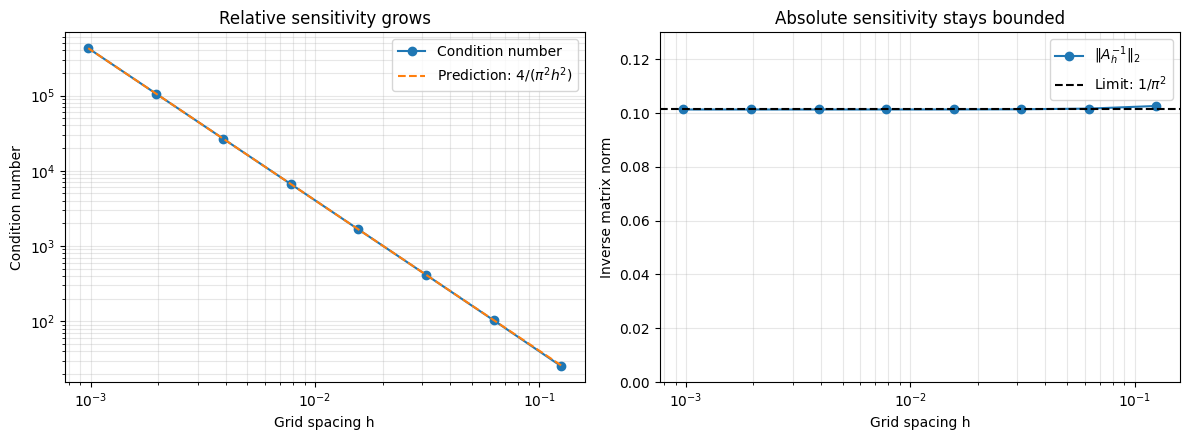

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: condition number
axes[0].loglog(
    hs_condition,
    condition_numbers,
    "o-",
    label="Condition number"
)

axes[0].loglog(
    hs_condition,
    4.0 / (np.pi**2 * hs_condition**2),
    "--",
    label=r"Prediction: $4/(\pi^2 h^2)$"
)

axes[0].set_xlabel("Grid spacing h")
axes[0].set_ylabel("Condition number")
axes[0].set_title("Relative sensitivity grows")
axes[0].legend()

# Right: absolute sensitivity in the Euclidean norm
inverse_norms = 1.0 / lambda_min

axes[1].semilogx(
    hs_condition,
    inverse_norms,
    "o-",
    label=r"$\|A_h^{-1}\|_2$"
)

axes[1].axhline(
    1.0 / np.pi**2,
    color="black",
    linestyle="--",
    label=r"Limit: $1/\pi^2$"
)

axes[1].set_xlabel("Grid spacing h")
axes[1].set_ylabel("Inverse matrix norm")
axes[1].set_title("Absolute sensitivity stays bounded")
axes[1].set_ylim(0.0, 0.13)
axes[1].legend()

for ax in axes:
    ax.grid(True, which="both", alpha=0.3)

fig.tight_layout()
plt.show()

### Can a stable method have a growing condition number?

Yes!

The eigenvalues behave as


$$
\lambda_{\min}(A_h)\longrightarrow\pi^2,
\qquad
\lambda_{\max}(A_h)\approx\frac{4}{h^2}.
$$


Thus, the smallest eigenvalue stays away from zero, while the largest
one grows. 

Therefore,


$$
\|A_h^{-1}\|_2
=
\frac{1}{\lambda_{\min}(A_h)}
\longrightarrow\frac{1}{\pi^2},
$$


but


$$
\kappa_2(A_h)
=
\frac{\lambda_{\max}(A_h)}{\lambda_{\min}(A_h)}
\longrightarrow\infty.
$$


The lecture also proves the maximum-norm stability estimate


$$
\|A_h^{-1}\|_\infty\le\frac18.
$$


This bound is independent of the mesh spacing.

**Takeaway:** stability controls absolute amplification of disturbances;
conditioning controls worst-case relative amplification.

**Keep the norms separate:** the spectral calculation uses the Euclidean
norm, while the lectures barrier argument uses the maximum norm.
Both demonstrate mesh-independent bounds for the inverse.


## 6. A small source perturbation with a visible effect

We now deliberately construct an example that nearly attains the
condition-number bound.

For this experiment only, use homogeneous boundary conditions:


$$
u(0)=u(1)=0.
$$


This keeps boundary contributions out of the right-hand side.

The eigenvectors of the discrete Poisson matrix are sampled sine waves.


We choose:

- an original source in the highest-frequency mode;
- a small perturbation in the lowest-frequency mode.

At the interior grid points,


$$
b_i=\sin\left(\frac{(M-1)\pi i}{M}\right),
\qquad
\delta b_i=\varepsilon\sin\left(\frac{\pi i}{M}\right).
$$


Solving divides each mode by its eigenvalue:


$$
\mathbf U=\frac{\mathbf b}{\lambda_{\max}},
\qquad
\delta\mathbf U=\frac{\delta\mathbf b}{\lambda_{\min}}.
$$


The source mode is strongly suppressed, while the perturbation mode is
suppressed much less. Consequently,


$$
\frac{\|\delta\mathbf U\|_2/\|\mathbf U\|_2}
     {\|\delta\mathbf b\|_2/\|\mathbf b\|_2}
=
\kappa_2(A_h).
$$


This is a deliberately chosen worst-case example, not a claim about
every source.

We compare two discrete solutions here; we are not measuring
discretization error against a continuous exact solution.

In [10]:
M_sensitivity = 64
epsilon = 1e-4  # Approximately a 0.01% relative source perturbation


def source_original(x):
    return np.sin((M_sensitivity - 1) * np.pi * x)


def source_perturbed(x):
    return source_original(x) + epsilon * np.sin(np.pi * x)


# Reuse the solver defined earlier in the notebook.
x, U_original = solve_poisson(
    source_original,
    M_sensitivity,
    g_left=0.0,
    g_right=0.0,
)

_, U_perturbed = solve_poisson(
    source_perturbed,
    M_sensitivity,
    g_left=0.0,
    g_right=0.0,
)

x_interior = x[1:-1]
b_original = source_original(x_interior)
b_perturbed = source_perturbed(x_interior)

relative_source_change = (
    np.linalg.norm(b_perturbed - b_original)
    / np.linalg.norm(b_original)
)

relative_solution_change = (
    np.linalg.norm(U_perturbed[1:-1] - U_original[1:-1])
    / np.linalg.norm(U_original[1:-1])
)

measured_amplification = (
    relative_solution_change / relative_source_change
)

predicted_condition = poisson_spectrum(M_sensitivity)[2]

print(f"Relative source change:   {relative_source_change:.3e}")
print(f"Relative solution change: {relative_solution_change:.3e}")
print()
print(f"Source change:   {100 * relative_source_change:.4f}%")
print(f"Solution change: {100 * relative_solution_change:.2f}%")
print()
print(f"Measured amplification: {measured_amplification:.3f}")
print(f"Condition number:       {predicted_condition:.3f}")

Relative source change:   1.000e-04
Relative solution change: 1.659e-01

Source change:   0.0100%
Solution change: 16.59%

Measured amplification: 1659.380
Condition number:       1659.380


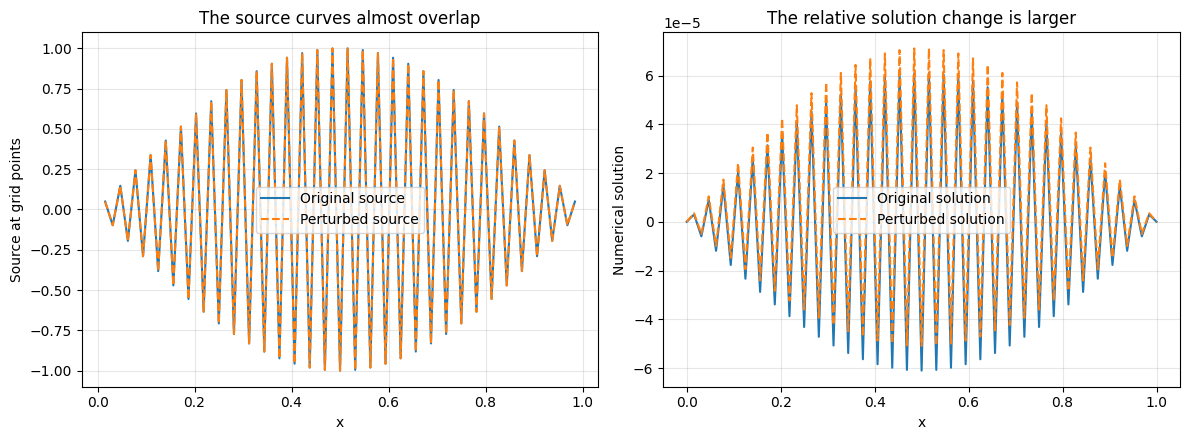

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(
    x_interior, b_original,
    label="Original source", linewidth=1.5
)
axes[0].plot(
    x_interior, b_perturbed,
    "--", label="Perturbed source", linewidth=1.5
)
axes[0].set_title("The source curves almost overlap")
axes[0].set_ylabel("Source at grid points")

axes[1].plot(
    x, U_original,
    label="Original solution", linewidth=1.5
)
axes[1].plot(
    x, U_perturbed,
    "--", label="Perturbed solution", linewidth=1.5
)
axes[1].set_title("The relative solution change is larger")
axes[1].set_ylabel("Numerical solution")
axes[1].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))

for ax in axes:
    ax.set_xlabel("x")
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.tight_layout()
plt.show()

## 7. What should we remember?

1. **Refinement improves discretization accuracy**, provided the solution
   has the required smoothness. 

2. **Refinement also increases the condition number**, approximately
   like $h^{-2}$ for this Poisson matrix.
   
3. **A growing condition number does not contradict stability:** the
   inverse remains bounded while the largest eigenvalue grows.
   [

4. **The condition number is a worst-case measure.**
   Different perturbation directions can behave very differently.

5. **Conditioning matters for numerical linear algebra.**
   For example, preconditioning becomes important when using conjugate
   gradients on increasingly fine grids. 

### Questions

1. If $M$ doubles, approximately how does the condition number change?

2. Repeat the sensitivity experiment with `M_sensitivity = 32` and `128`.
   Keep `epsilon` fixed. What happens to the relative solution change?

3. Replace the perturbation by a small multiple of the original source:

   `return (1.0 + epsilon) * source_original(x)`

   Why is the relative amplification now approximately one?

4. Does multiplying both sides of the system by $h^2$ improve its
   condition number?

   Hint:

   
$$
\kappa_2(cA)=\kappa_2(A)
   \qquad\text{for }c\ne0.
$$


5. Explain the difference between:
   - discretization error;
   - sensitivity to perturbed data;
   - error from an inexact linear solve.

# 8. Poisson's equation in two dimensions

We now solve on the unit square:


$$
-\Delta u
=
-\frac{\partial^2u}{\partial x^2}
-\frac{\partial^2u}{\partial y^2}
=f(x,y),
\qquad (x,y)\in(0,1)^2.
$$


Dirichlet conditions prescribe $u=g$ on all four sides of the square.

## A tilted surface with a smooth hill

Choose the exact solution


$$
u(x,y)=1+x+y+2\sin(\pi x)\sin(\pi y).
$$


Differentiating gives the source


$$
f(x,y)=4\pi^2\sin(\pi x)\sin(\pi y).
$$


Because the sine product vanishes on the boundary, the boundary values are


$$
g(x,y)=1+x+y.
$$


We know the exact solution, so we can visualize not only the numerical
solution but also its error.

**Physical picture:** the boundary temperatures form a tilted plane,
while a positive heat source creates a warm region in the interior.

## The five-point stencil

Let $N_x$ and $N_y$ be the numbers of interior points in each direction:


$$
h_x=\frac{1}{N_x+1},
\qquad
h_y=\frac{1}{N_y+1}.
$$


At each interior point, use


$$
\frac{2U_{ij}-U_{i-1,j}-U_{i+1,j}}{h_x^2}
+
\frac{2U_{ij}-U_{i,j-1}-U_{i,j+1}}{h_y^2}
=f(x_i,y_j).
$$


This couples each unknown to its four axis neighbors.


### Array ordering

In the Python code, `U[j, i]` means the value at $(x_i,y_j)$:

- columns change the $x$-coordinate;
- rows change the $y$-coordinate.

Flattening this array row by row makes the $x$-index vary fastest,
matching the lecture's ordering. 

With one-dimensional difference matrices $A_x$ and $A_y$,


$$
A=I_y\otimes A_x+A_y\otimes I_x.
$$


This is the sparse Kronecker-product construction from the lecture.


**Boundary treatment:** whenever a neighbor lies on the boundary,
move its known value to the right-hand side.


In [12]:
from scipy.sparse import diags, eye, kron
from scipy.sparse.linalg import spsolve


def solve_poisson_2d(f, g, Nx=63, Ny=None):
    """
    Solve -Delta u = f on the unit square, with u = g on its boundary.

    Parameters
    ----------
    f, g : callable
        Functions accepting NumPy coordinate arrays.
    Nx, Ny : int
        Numbers of interior points in the x and y directions.
        If Ny is omitted, use Ny = Nx.

    Returns
    -------
    X, Y : 2D arrays
        Coordinates, including boundary points.
    U : 2D array
        Numerical solution, with U[j, i] at (x_i, y_j).
    """
    if Ny is None:
        Ny = Nx

    if Nx < 2 or Ny < 2:
        raise ValueError("Use at least two interior points per direction.")

    hx = 1.0 / (Nx + 1)
    hy = 1.0 / (Ny + 1)

    x = np.linspace(0.0, 1.0, Nx + 2)
    y = np.linspace(0.0, 1.0, Ny + 2)

    X, Y = np.meshgrid(x, y, indexing="xy")
    Xi, Yi = X[1:-1, 1:-1], Y[1:-1, 1:-1]

    # One-dimensional approximations to -d²/dx² and -d²/dy²
    Ax = diags(
        [-np.ones(Nx - 1), 2.0 * np.ones(Nx), -np.ones(Nx - 1)],
        offsets=[-1, 0, 1],
        format="csc",
    ) / hx**2

    Ay = diags(
        [-np.ones(Ny - 1), 2.0 * np.ones(Ny), -np.ones(Ny - 1)],
        offsets=[-1, 0, 1],
        format="csc",
    ) / hy**2

    # x varies fastest in the flattened vector.
    A = (
        kron(eye(Ny, format="csc"), Ax, format="csc")
        + kron(Ay, eye(Nx, format="csc"), format="csc")
    )

    # Interior source values.
    # broadcast_to also allows a constant source such as f(x,y) = 1.
    B = np.array(
        np.broadcast_to(f(Xi, Yi), Xi.shape),
        dtype=float,
        copy=True,
    )

    # Boundary contributions: left, right, bottom, top
    B[:, 0]  += g(0.0, y[1:-1]) / hx**2
    B[:, -1] += g(1.0, y[1:-1]) / hx**2
    B[0, :]  += g(x[1:-1], 0.0) / hy**2
    B[-1, :] += g(x[1:-1], 1.0) / hy**2

    # Flatten -> solve -> reshape
    u_interior = spsolve(A, B.ravel(order="C"))

    U = np.zeros_like(X)
    U[1:-1, 1:-1] = u_interior.reshape((Ny, Nx), order="C")

    # Attach the prescribed boundary values
    U[:, 0]  = g(0.0, y)
    U[:, -1] = g(1.0, y)
    U[0, :]  = g(x, 0.0)
    U[-1, :] = g(x, 1.0)

    return X, Y, U

In [13]:
def exact_2d(x, y):
    return (
        1.0 + x + y
        + 2.0 * np.sin(np.pi * x) * np.sin(np.pi * y)
    )


def source_2d(x, y):
    return (
        4.0 * np.pi**2
        * np.sin(np.pi * x) * np.sin(np.pi * y)
    )


def boundary_2d(x, y):
    return 1.0 + x + y


# 63 × 63 interior unknowns
N = 63

X, Y, U_2d = solve_poisson_2d(
    source_2d, boundary_2d, Nx=N
)

U_exact_2d = exact_2d(X, Y)
error_2d = np.abs(U_2d - U_exact_2d)

print(f"Interior unknowns: {N} × {N} = {N**2}")
print(f"Grid spacing:      {1.0 / (N + 1):.5f}")
print(f"Maximum error:     {error_2d.max():.6e}")

# Verify all four boundary conditions
assert np.allclose(U_2d[:, 0], boundary_2d(X[:, 0], Y[:, 0]))
assert np.allclose(U_2d[:, -1], boundary_2d(X[:, -1], Y[:, -1]))
assert np.allclose(U_2d[0, :], boundary_2d(X[0, :], Y[0, :]))
assert np.allclose(U_2d[-1, :], boundary_2d(X[-1, :], Y[-1, :]))

Interior unknowns: 63 × 63 = 3969
Grid spacing:      0.01562
Maximum error:     4.016436e-04


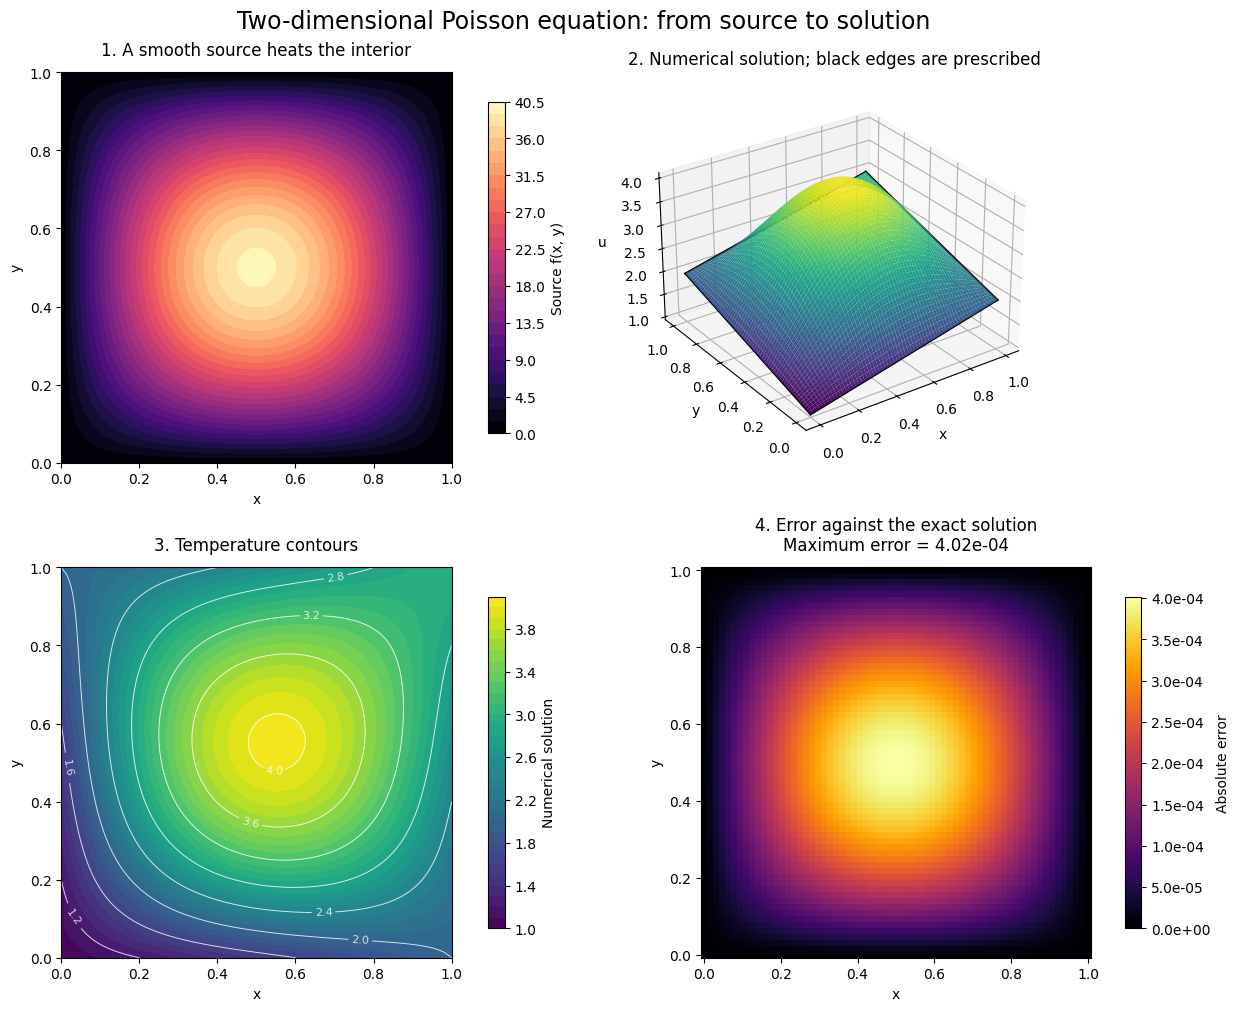

In [14]:
fig = plt.figure(figsize=(13, 10), constrained_layout=True)

ax_source = fig.add_subplot(2, 2, 1)
ax_surface = fig.add_subplot(2, 2, 2, projection="3d")
ax_solution = fig.add_subplot(2, 2, 3)
ax_error = fig.add_subplot(2, 2, 4)

# --------------------------------------------------
# 1. Source: where heat is generated
# --------------------------------------------------
source_plot = ax_source.contourf(
    X, Y, source_2d(X, Y),
    levels=30, cmap="magma"
)
fig.colorbar(
    source_plot, ax=ax_source, shrink=0.85,
    label="Source f(x, y)"
)

ax_source.set_title("1. A smooth source heats the interior", pad=12)

# --------------------------------------------------
# 2. Numerical solution as a 3D surface
# --------------------------------------------------
ax_surface.plot_surface(
    X, Y, U_2d,
    cmap="viridis",
    rcount=80, ccount=80,
    linewidth=0,
    antialiased=True,
    alpha=0.98,
)

# Draw the four prescribed boundary curves
for edge in [
    (X[0, :], Y[0, :], U_2d[0, :]),
    (X[-1, :], Y[-1, :], U_2d[-1, :]),
    (X[:, 0], Y[:, 0], U_2d[:, 0]),
    (X[:, -1], Y[:, -1], U_2d[:, -1]),
]:
    ax_surface.plot(*edge, color="black", linewidth=1.5)

ax_surface.view_init(elev=28, azim=-125)
ax_surface.set_box_aspect((1, 1, 0.65))
ax_surface.set_xlabel("x")
ax_surface.set_ylabel("y")
ax_surface.set_zlabel("u")
ax_surface.set_title("2. Numerical solution; black edges are prescribed")

# --------------------------------------------------
# 3. Solution viewed from above
# --------------------------------------------------
solution_plot = ax_solution.contourf(
    X, Y, U_2d,
    levels=30, cmap="viridis"
)

contours = ax_solution.contour(
    X, Y, U_2d,
    levels=8, colors="white",
    linewidths=0.7, alpha=0.8
)
ax_solution.clabel(contours, inline=True, fontsize=8, fmt="%.1f")

fig.colorbar(
    solution_plot, ax=ax_solution, shrink=0.85,
    label="Numerical solution"
)
ax_solution.set_title("3. Temperature contours", pad=12)

# --------------------------------------------------
# 4. Absolute error
# --------------------------------------------------
error_plot = ax_error.pcolormesh(
    X, Y, error_2d,
    shading="auto", cmap="inferno"
)
fig.colorbar(
    error_plot, ax=ax_error, shrink=0.85,
    label="Absolute error", format="%.1e"
)
ax_error.set_title(
    f"4. Error against the exact solution\n"
    f"Maximum error = {error_2d.max():.2e}",
    pad=12,
)

for ax in (ax_source, ax_solution, ax_error):
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal")

fig.suptitle(
    "Two-dimensional Poisson equation: from source to solution",
    fontsize=17,
)

plt.show()

     M     Unknowns    Maximum error    Order
------------------------------------------------
     8           49      2.59015e-02       --
    16          225      6.43793e-03    2.008
    32          961      1.60716e-03    2.002
    64         3969      4.01644e-04    2.001
   128        16129      1.00402e-04    2.000


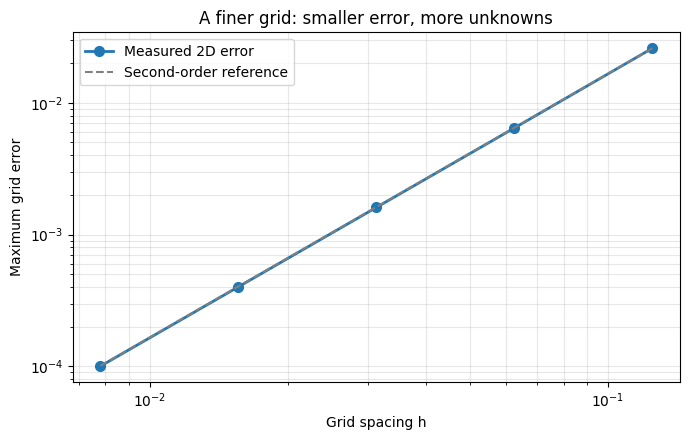

In [15]:
# Number of subintervals in EACH direction
Ms_2d = np.array([8, 16, 32, 64, 128])
hs_2d = 1.0 / Ms_2d

errors_2d = []

for M in Ms_2d:
    Xh, Yh, Uh = solve_poisson_2d(
        source_2d, boundary_2d,
        Nx=int(M - 1),
    )

    error = np.max(np.abs(Uh - exact_2d(Xh, Yh)))
    errors_2d.append(error)

errors_2d = np.array(errors_2d)

orders_2d = np.full(len(Ms_2d), np.nan)
orders_2d[1:] = np.log2(errors_2d[:-1] / errors_2d[1:])

print(f"{'M':>6} {'Unknowns':>12} {'Maximum error':>16} {'Order':>8}")
print("-" * 48)

for M, error, order in zip(Ms_2d, errors_2d, orders_2d):
    order_text = "--" if np.isnan(order) else f"{order:.3f}"
    print(f"{M:6d} {(M - 1)**2:12d} {error:16.5e} {order_text:>8}")

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.loglog(
    hs_2d, errors_2d,
    "o-", linewidth=2, markersize=7,
    label="Measured 2D error"
)

ax.loglog(
    hs_2d,
    errors_2d[0] * (hs_2d / hs_2d[0])**2,
    "--", color="gray",
    label="Second-order reference"
)

ax.set_xlabel("Grid spacing h")
ax.set_ylabel("Maximum grid error")
ax.set_title("A finer grid: smaller error, more unknowns")
ax.grid(True, which="both", alpha=0.3)
ax.legend()

fig.tight_layout()
plt.show()